# Vehicle Insurance Data: Exploratory Analysis

This notebook explores vehicle insurance CSV files stored with the project. It searches `archive/` and `datasets/` for `motor_data*.csv` files, loads every match, and combines them into one analysis table.

Run the notebook from the project directory. Edit the data source settings below to use other folders or a different filename pattern. Each row is treated as an insurance record; repeated `OBJECT_ID` values may represent the same vehicle across policy years.


## 1. Imports and data source settings

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

# Search these project-relative folders. Add or remove folders as needed.
DATA_DIRS = [Path("archive"), Path("datasets")]
FILE_PATTERN = "motor_data*.csv"
source_files = sorted(
    path for folder in DATA_DIRS if folder.exists()
    for path in folder.rglob(FILE_PATTERN)
)
if not source_files:
    searched = ", ".join(str(folder) for folder in DATA_DIRS)
    raise FileNotFoundError(
        f"No {FILE_PATTERN!r} files found in: {searched}. "
        "Place the CSV files in one of these folders or update DATA_DIRS."
    )
pd.DataFrame({"source_file": [str(path) for path in source_files]})


,source_file
0,archive/motor_data11-14lats.csv
1,archive/motor_data14-2018.csv


## 2. Load and combine the source files

The source filename is retained in `SOURCE_FILE` so results can be traced back to their CSV. Full files are loaded; no arbitrary row limit is applied.

In [2]:
frames = []
for path in source_files:
    frame = pd.read_csv(path, low_memory=False)
    frame["SOURCE_FILE"] = path.name
    frames.append(frame)

raw_df = pd.concat(frames, ignore_index=True, sort=False)
print(f"Loaded {len(source_files)} file(s) and {len(raw_df):,} records.")
raw_df.head()


Loaded 2 file(s) and 802,036 records.


,SEX,INSR_BEGIN,INSR_END,EFFECTIVE_YR,INSR_TYPE,INSURED_VALUE,PREMIUM,OBJECT_ID,PROD_YEAR,SEATS_NUM,CARRYING_CAPACITY,TYPE_VEHICLE,CCM_TON,MAKE,USAGE,CLAIM_PAID,SOURCE_FILE
0,0,08-AUG-13,07-AUG-14,08,1202,519755.22,7209.140,5000029885,2007.0,4.0,6.0,Pick-up,3153.0,NISSAN,Own Goods,NaN,motor_data11-14lats.csv
1,0,08-AUG-12,07-AUG-13,08,1202,519755.22,7203.890,5000029885,2007.0,4.0,6.0,Pick-up,3153.0,NISSAN,Own Goods,NaN,motor_data11-14lats.csv
2,0,08-AUG-11,07-AUG-12,08,1202,519755.22,7045.804,5000029885,2007.0,4.0,6.0,Pick-up,3153.0,NISSAN,Own Goods,NaN,motor_data11-14lats.csv
3,0,08-JUL-11,07-AUG-11,08,1202,519755.22,287.250,5000029885,2007.0,4.0,6.0,Pick-up,3153.0,NISSAN,Own Goods,NaN,motor_data11-14lats.csv
4,0,08-AUG-13,07-AUG-14,08,1202,285451.24,4286.900,5000029901,2010.0,4.0,7.0,Pick-up,2494.0,TOYOTA,Own Goods,19894.43,motor_data11-14lats.csv


## 3. Initial review

In [3]:
print(f"Rows: {raw_df.shape[0]:,} | Columns: {raw_df.shape[1]:,}")
print("\nColumns:")
print(raw_df.columns.tolist())
raw_df.info()


Rows: 802,036 | Columns: 17

Columns:
['SEX', 'INSR_BEGIN', 'INSR_END', 'EFFECTIVE_YR', 'INSR_TYPE', 'INSURED_VALUE', 'PREMIUM', 'OBJECT_ID', 'PROD_YEAR', 'SEATS_NUM', 'CARRYING_CAPACITY', 'TYPE_VEHICLE', 'CCM_TON', 'MAKE', 'USAGE', 'CLAIM_PAID', 'SOURCE_FILE']
<class 'pandas.DataFrame'>
RangeIndex: 802036 entries, 0 to 802035
Data columns (total 17 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   SEX                802036 non-null  int64  
 1   INSR_BEGIN         802036 non-null  str    
 2   INSR_END           802036 non-null  str    
 3   EFFECTIVE_YR       802032 non-null  str    
 4   INSR_TYPE          802036 non-null  int64  
 5   INSURED_VALUE      802036 non-null  float64
 6   PREMIUM            802015 non-null  float64
 7   OBJECT_ID          802036 non-null  int64  
 8   PROD_YEAR          801867 non-null  float64
 9   SEATS_NUM          801801 non-null  float64
 10  CARRYING_CAPACITY  603837 non-null  float64
 

In [4]:
raw_df.sample(min(5, len(raw_df)), random_state=42)


,SEX,INSR_BEGIN,INSR_END,EFFECTIVE_YR,INSR_TYPE,INSURED_VALUE,PREMIUM,OBJECT_ID,PROD_YEAR,SEATS_NUM,CARRYING_CAPACITY,TYPE_VEHICLE,CCM_TON,MAKE,USAGE,CLAIM_PAID,SOURCE_FILE
107048,1,24-NOV-11,23-NOV-12,11,1202,60000.0,1608.10,5000156548,2010.0,3.0,3.0,Motor-cycle,173.0,BAJAJ,Fare Paying Passengers,NaN,motor_data11-14lats.csv
571612,0,12-NOV-16,11-NOV-17,14,1202,2400000.0,14595.13,5000667900,2013.0,4.0,6.0,Pick-up,4164.0,TOYOTA,Own Goods,NaN,motor_data14-2018.csv
207349,1,21-JUL-13,20-JUL-14,12,1201,379000.0,5164.13,5000319903,2012.0,4.0,NaN,Automobile,1800.0,LIFAN,Private,NaN,motor_data11-14lats.csv
398016,0,05-JAN-17,04-JAN-18,11,1201,0.0,1069.60,5000166544,1996.0,8.0,8.0,Station Wagones,4169.0,NISSAN,Private,NaN,motor_data14-2018.csv
544340,1,24-AUG-17,23-AUG-18,12,1201,0.0,541.30,5000613110,1979.0,4.0,NaN,Automobile,1290.0,TOYOTA,Private,NaN,motor_data14-2018.csv


## 4. Clean fields and inspect missing values

Numeric fields are parsed as numbers and policy dates as dates. Invalid or blank values remain missing (`NaN`/`NaT`); this notebook does not invent replacement values. `EFFECTIVE_YR` is retained as a category because values such as `08` are codes, not full calendar years.

In [5]:
df = raw_df.copy()
df.columns = df.columns.str.strip()

# Trim text fields and treat whitespace-only cells as missing.
text_columns = df.select_dtypes(include=["object", "string"]).columns
for column in text_columns:
    df[column] = df[column].astype("string").str.strip().replace("", pd.NA)

numeric_columns = [
    "INSURED_VALUE", "PREMIUM", "PROD_YEAR", "SEATS_NUM",
    "CARRYING_CAPACITY", "CCM_TON", "CLAIM_PAID",
]
for column in numeric_columns:
    if column in df.columns:
        df[column] = pd.to_numeric(df[column], errors="coerce")

for column in ["INSR_BEGIN", "INSR_END"]:
    if column in df.columns:
        df[column] = pd.to_datetime(df[column], format="%d-%b-%y", errors="coerce")

missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
})
missing.sort_values("missing_percent", ascending=False)


,missing_count,missing_percent
CLAIM_PAID,741891,92.50
CARRYING_CAPACITY,198199,24.71
SEATS_NUM,235,0.03
PROD_YEAR,169,0.02
USAGE,0,0.00
MAKE,5,0.00
CCM_TON,8,0.00
TYPE_VEHICLE,0,0.00
SEX,0,0.00
INSR_BEGIN,0,0.00


## 5. Dataset summary

In [6]:
summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_missing": df.notna().sum(),
    "missing": df.isna().sum(),
    "unique_values": df.nunique(dropna=True),
})
summary


,dtype,non_missing,missing,unique_values
SEX,int64,802036,0,3
INSR_BEGIN,datetime64[us],802036,0,2556
INSR_END,datetime64[us],802036,0,2834
EFFECTIVE_YR,string,802032,4,151
INSR_TYPE,int64,802036,0,3
INSURED_VALUE,float64,802036,0,17437
PREMIUM,float64,802015,21,276433
OBJECT_ID,int64,802036,0,288763
PROD_YEAR,float64,801867,169,69
SEATS_NUM,float64,801801,235,96


In [7]:
df.select_dtypes(include="number").describe().T


,count,mean,std,min,25%,50%,75%,max
SEX,802036.0,5.670918e-01,6.444297e-01,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,2.000000e+00
INSR_TYPE,802036.0,1.201742e+03,4.403215e-01,1.201000e+03,1.201000e+03,1.202000e+03,1.202000e+03,1.204000e+03
INSURED_VALUE,802036.0,5.091294e+05,9.017833e+05,0.000000e+00,0.000000e+00,1.800000e+05,7.300000e+05,2.500000e+08
PREMIUM,802015.0,7.406987e+03,1.352456e+04,0.000000e+00,7.557000e+02,3.376550e+03,9.643270e+03,7.581230e+06
OBJECT_ID,802036.0,5.000453e+09,3.444165e+05,5.000018e+09,5.000160e+09,5.000380e+09,5.000718e+09,5.001351e+09
PROD_YEAR,801867.0,2.004534e+03,1.022798e+01,1.950000e+03,2.000000e+03,2.008000e+03,2.012000e+03,2.018000e+03
SEATS_NUM,801801.0,6.130357e+00,1.340349e+01,0.000000e+00,1.000000e+00,4.000000e+00,4.000000e+00,1.990000e+02
CARRYING_CAPACITY,603837.0,4.978776e+02,3.861218e+03,0.000000e+00,0.000000e+00,6.000000e+00,3.500000e+01,1.000000e+06
CCM_TON,802028.0,3.172698e+03,3.445455e+03,0.000000e+00,2.000000e+02,2.494000e+03,4.164000e+03,2.000000e+04
CLAIM_PAID,60145.0,2.564802e+05,1.495336e+06,0.000000e+00,1.350000e+04,3.463352e+04,1.338690e+05,1.524458e+08


## 6. Explore the records

### Insurance records by vehicle type

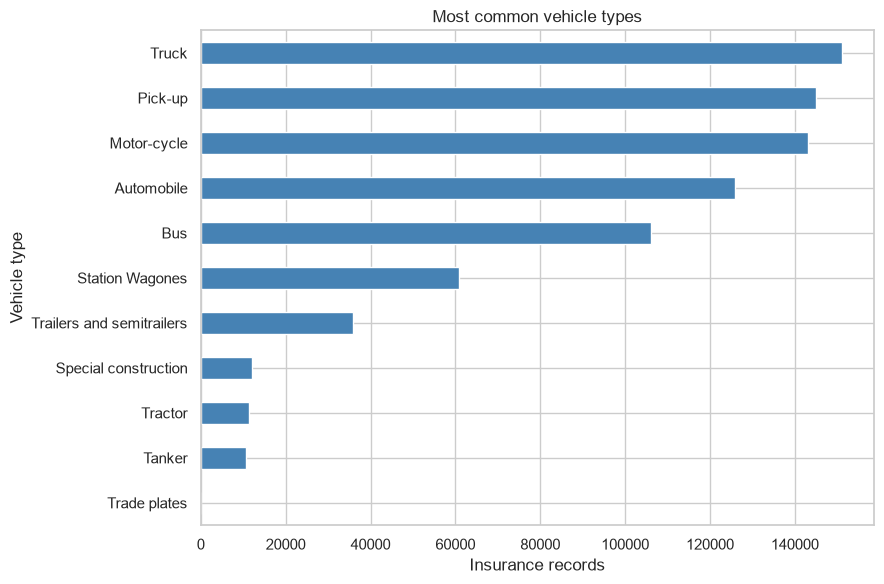

In [8]:
if "TYPE_VEHICLE" in df.columns:
    counts = df["TYPE_VEHICLE"].value_counts().head(15).sort_values()
    ax = counts.plot(kind="barh", figsize=(9, 6), color="steelblue")
    ax.set(title="Most common vehicle types", xlabel="Insurance records", ylabel="Vehicle type")
    plt.tight_layout()
    plt.show()


### Most common vehicle makes

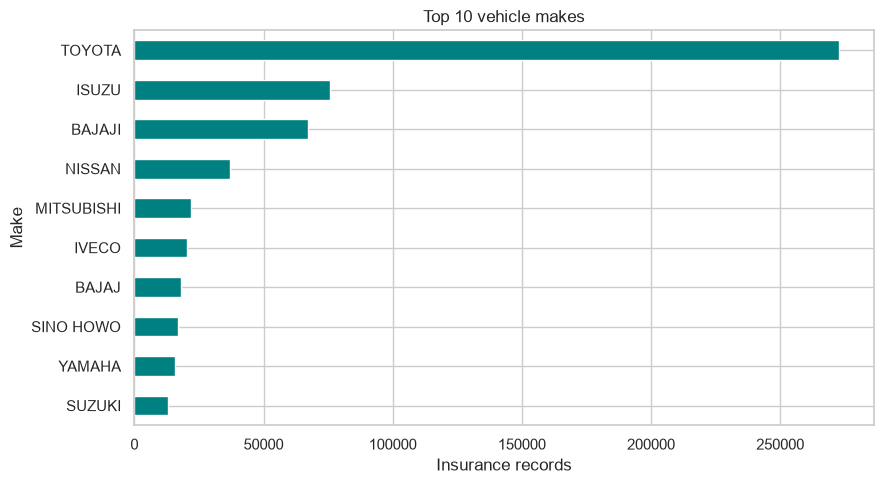

In [9]:
if "MAKE" in df.columns:
    counts = df["MAKE"].value_counts().head(10).sort_values()
    ax = counts.plot(kind="barh", figsize=(9, 5), color="teal")
    ax.set(title="Top 10 vehicle makes", xlabel="Insurance records", ylabel="Make")
    plt.tight_layout()
    plt.show()


### Insurance start dates

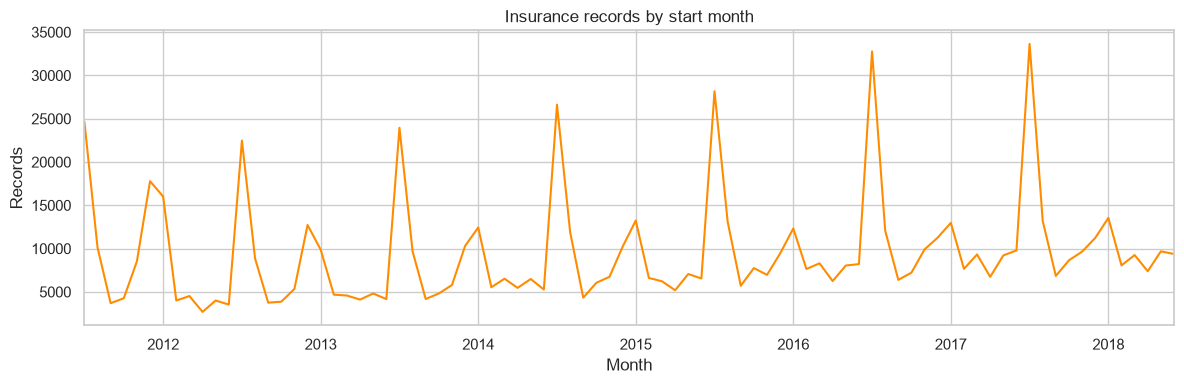

In [10]:
if "INSR_BEGIN" in df.columns:
    monthly = (df.dropna(subset=["INSR_BEGIN"]).set_index("INSR_BEGIN").resample("MS").size())
    ax = monthly.plot(figsize=(12, 4), color="darkorange")
    ax.set(title="Insurance records by start month", xlabel="Month", ylabel="Records")
    plt.tight_layout()
    plt.show()


### Premium and insured value distributions

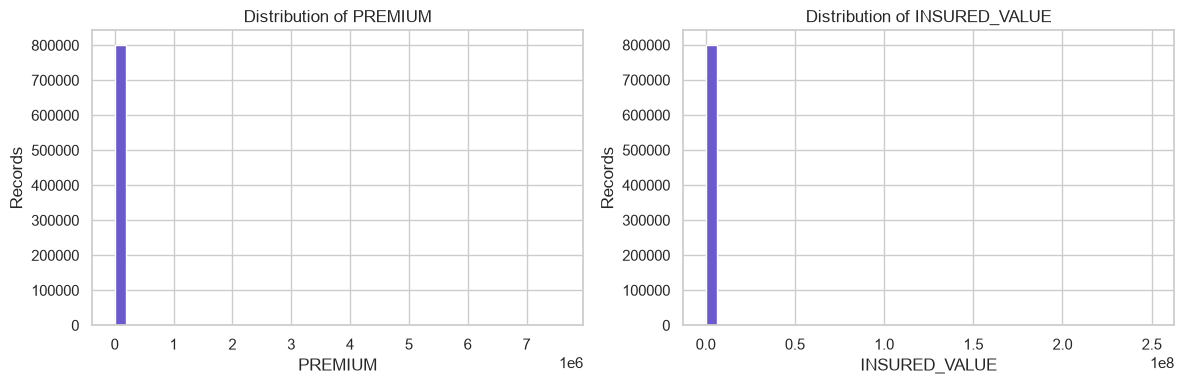

In [11]:
plot_columns = [c for c in ["PREMIUM", "INSURED_VALUE"] if c in df.columns]
if plot_columns:
    fig, axes = plt.subplots(1, len(plot_columns), figsize=(6 * len(plot_columns), 4))
    axes = np.atleast_1d(axes)
    for ax, column in zip(axes, plot_columns):
        ax.hist(df[column].dropna(), bins=40, color="slateblue", edgecolor="white")
        ax.set(title=f"Distribution of {column}", xlabel=column, ylabel="Records")
    plt.tight_layout()
    plt.show()


### Engine capacity by make

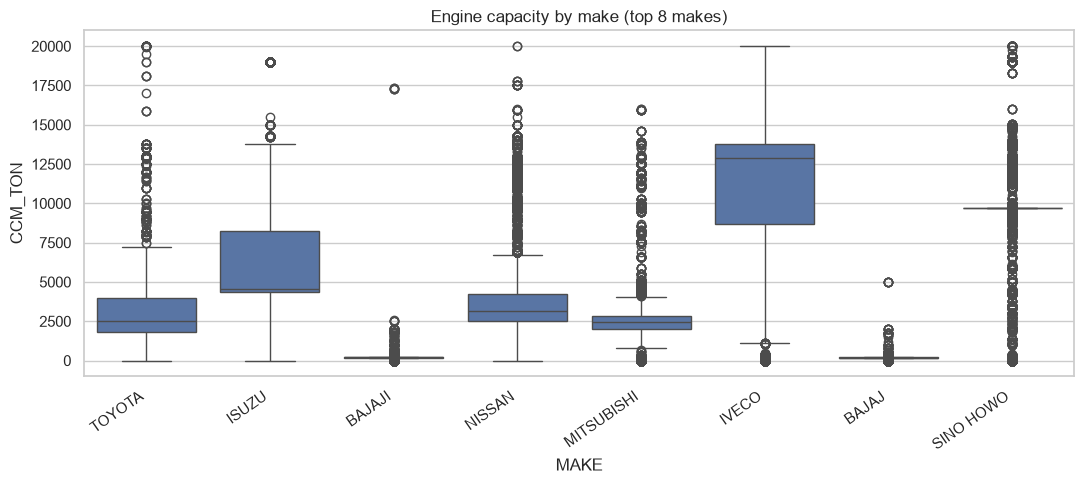

In [12]:
if {"MAKE", "CCM_TON"}.issubset(df.columns):
    top_makes = df["MAKE"].value_counts().head(8).index
    plot_data = df.loc[df["MAKE"].isin(top_makes), ["MAKE", "CCM_TON"]].dropna()
    if not plot_data.empty:
        plt.figure(figsize=(11, 5))
        sns.boxplot(data=plot_data, x="MAKE", y="CCM_TON", order=top_makes)
        plt.xticks(rotation=35, ha="right")
        plt.title("Engine capacity by make (top 8 makes)")
        plt.tight_layout()
        plt.show()


## 7. Questions answered from the data

These summaries use all loaded records. Missing numeric values are excluded from calculations and are not treated as zero.

In [13]:
if "CCM_TON" in df.columns:
    capacity = df["CCM_TON"].dropna()
    if not capacity.empty:
        print(f"Lowest CCM_TON: {capacity.min():,.2f}")
        print(f"Highest CCM_TON: {capacity.max():,.2f}")
        cols = [c for c in ["MAKE", "TYPE_VEHICLE", "PROD_YEAR", "CCM_TON"] if c in df.columns]
        print("Records with highest CCM_TON:")
        print(df.loc[df["CCM_TON"].eq(capacity.max()), cols].head(10).to_string(index=False))

if "MAKE" in df.columns and df["MAKE"].notna().any():
    print(f"Most frequent make: {df['MAKE'].mode().iloc[0]}")
for column in ["PREMIUM", "INSURED_VALUE"]:
    if column in df.columns:
        print(f"Mean {column}: {df[column].mean():,.2f}")
if "TYPE_VEHICLE" in df.columns:
    print("\nRecords by vehicle type:")
    print(df["TYPE_VEHICLE"].value_counts(dropna=False).to_string())


Lowest CCM_TON: 0.00
Highest CCM_TON: 20,000.00
Records with highest CCM_TON:
     MAKE TYPE_VEHICLE  PROD_YEAR  CCM_TON
    IVECO        Truck     2012.0  20000.0
SINO HOWO        Truck     2012.0  20000.0
SINO HOWO        Truck     2012.0  20000.0
    IVECO        Truck     2012.0  20000.0
    IVECO        Truck     2012.0  20000.0
SINO HOWO        Truck     2012.0  20000.0
SINO HOWO        Truck     2012.0  20000.0
SINO HOWO        Truck     2012.0  20000.0
SINO HOWO        Truck     2012.0  20000.0
SINO HOWO        Truck     2012.0  20000.0
Most frequent make: TOYOTA
Mean PREMIUM: 7,406.99
Mean INSURED_VALUE: 509,129.43

Records by vehicle type:
TYPE_VEHICLE
Truck                        151088
Pick-up                      144874
Motor-cycle                  143186
Automobile                   125993
Bus                          106015
Station Wagones               60785
Trailers and semitrailers     35954
Special construction          12077
Tractor                       11414
Tanke

### Relationship between insured value and engine capacity

Pearson correlation: 0.309


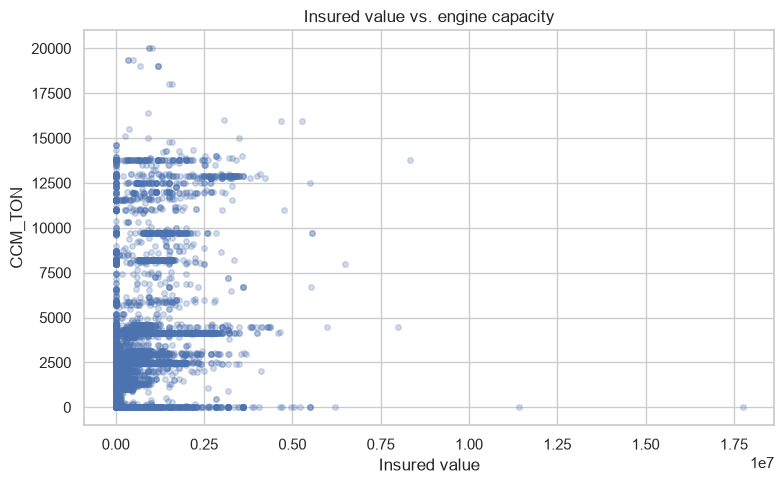

In [14]:
if {"INSURED_VALUE", "CCM_TON"}.issubset(df.columns):
    relationship = df[["INSURED_VALUE", "CCM_TON"]].dropna()
    if len(relationship) >= 2:
        print(f"Pearson correlation: {relationship.corr().iloc[0, 1]:.3f}")
        # Sample only for chart readability; calculations above use all records.
        chart_data = relationship.sample(min(10_000, len(relationship)), random_state=42)
        plt.figure(figsize=(8, 5))
        plt.scatter(chart_data["INSURED_VALUE"], chart_data["CCM_TON"], alpha=0.25, s=16)
        plt.xlabel("Insured value")
        plt.ylabel("CCM_TON")
        plt.title("Insured value vs. engine capacity")
        plt.tight_layout()
        plt.show()


## 8. Interpretation notes

- Each row represents a record in the source files. Repeated object identifiers may occur across policy years, so row counts should not be described as unique vehicle counts without deduplicating by `OBJECT_ID`.
- The source contains coded fields such as `SEX`, `INSR_TYPE`, and `EFFECTIVE_YR`. Interpret codes only with a reliable data dictionary.
- Claims about policyholder age, marital status, anti-theft devices, and coverage are omitted because these CSVs do not contain those fields.
- Review missing values before modeling or drawing conclusions. Choose imputation based on the analysis goal instead of filling missing values with arbitrary constants.
